# Lab 6.2 Autoencoder

In this notebook you will explore building an autoencoder with images of cranberries.

The dataset comes from the USDA: "[Images and bounding box annotations of sound and rotten cranberry fruit from a postharvest imaging platform.](https://agdatacommons.nal.usda.gov/articles/dataset/Images_and_bounding_box_annotations_of_sound_and_rotten_cranberry_fruit_from_a_postharvest_imaging_platform/31410369)" and includes images of "rotten" and "sound" cranberries, with labels.

I cropped out each cranberry into a separate image and stored them in either the "sound" or "rotten" directory, accordingly.

In [4]:
!wget -nc -q -O cranberry_dataset.zip "https://www.dropbox.com/scl/fi/sc5fkmr55yo6xzake289c/cranberry_dataset.zip?rlkey=95lfox4fuughk20cp9zxyg561&dl=1"
!unzip -n -q cranberry_dataset.zip

In [5]:
import torch
device = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'

In [6]:
import torch
import torch.nn as nn
import torchvision
import torchmetrics
import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm

Here we set up datasets to load the images and resize them to $32\times32$ pixels.

In [7]:
transforms = torchvision.transforms.Compose([
    torchvision.transforms.Resize((32, 32)),
    torchvision.transforms.ToTensor(),
])

train_ds_no_transform = torchvision.datasets.ImageFolder(
    'cranberry_dataset/',
)
train_ds = torchvision.datasets.ImageFolder(
    'cranberry_dataset/',
    transform=transforms
)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=32, shuffle=True)

In [8]:
train_ds

Dataset ImageFolder
    Number of datapoints: 3323
    Root location: cranberry_dataset/
    StandardTransform
Transform: Compose(
               Resize(size=(32, 32), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

Text(0.5, 1.0, 'rotten')

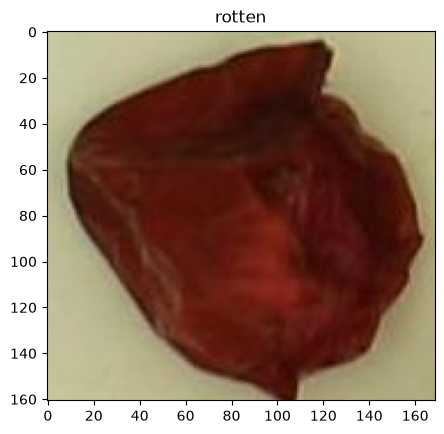

In [9]:
image,label = next(iter(train_ds_no_transform))
plt.imshow(image)
plt.title(train_ds.classes[label])

Text(0.5, 1.0, 'rotten')

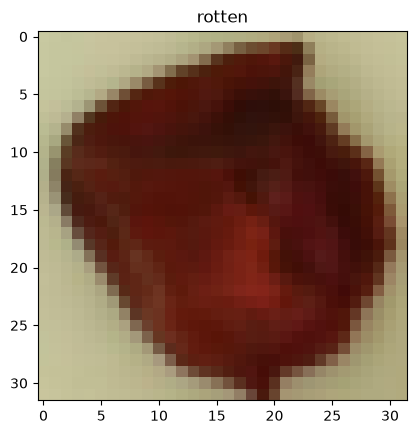

In [10]:
image,label = next(iter(train_ds))
plt.imshow(image.permute(1,2,0))
plt.title(train_ds.classes[label])

### Exercises

1. Complete this function to create separate encoder and decoder models, and then connect them in an autoencoder.

The encoder design:
- 2D convolution with kernel size 3x3, 16 output channels, stride 2, padding=1
- SiLU activation
- 2D convolution with kernel size 3x3, 32 output channels, stride 2, padding=1
- SiLU activation
- 2D convolution with kernel size 3x3, 64 output channels, stride 2, padding=1
- SiLU activation

The encoder design:
- 2D transpose convolution with kernel size 3x3, 16 output channels, stride 2, padding=1, output_padding=1
- SiLU activation
- 2D transpose convolution with kernel size 3x3, 32 output channels, stride 2, padding=1, output_padding=1
- SiLU activation
- 2D transpose convolution with kernel size 3x3, 64 output channels, stride 2, padding=1, output_padding=1
- Sigmoid activation, to make the output have range [0,1]

Connect them in a Sequential class that first runs the encoder and then the decoder -- this is the autoencoder.

Pass an image through the encoder, and then pass the encoder output through the decoder.  

What size output does the encoder have?

Verify that the output size of the decoder matches the size of the input to the encoder.


In [11]:
def make_autoencoder(device='cpu'):
    """ Make an autoencoder model with an encoder and decoder. 

        Arguments:
            device: The device to use for the model. Defaults to 'cpu'.
            
        Returns:
            encoder: The encoder model.
            decoder: The decoder model.
            autoencoder: The autoencoder model.
    """
    encoder = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, stride=2, padding=1),
        nn.SiLU(),
        nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
        nn.SiLU(),
        nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
        nn.SiLU(),
    ).to(device)

    decoder = nn.Sequential(
        nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
        nn.SiLU(),
        nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
        nn.SiLU(),
        nn.ConvTranspose2d(16, 3, kernel_size=3, stride=2, padding=1, output_padding=1),
        nn.Sigmoid(),
    ).to(device)

    autoencoder = nn.Sequential(encoder, decoder).to(device)
    return encoder, decoder, autoencoder

In [12]:
encoder, decoder, autoencoder = make_autoencoder(device=device)

In [13]:
image = next(iter(train_ds))[0].unsqueeze(0).to(device)
latents = encoder(image)
output = decoder(latents)
image.shape, latents.shape, output.shape

(torch.Size([1, 3, 32, 32]),
 torch.Size([1, 64, 4, 4]),
 torch.Size([1, 3, 32, 32]))

The encoder output has shape `[1, 64, 4, 4]`: each stride-2 convolution cuts the size of image in half from 32 to 4, while the channels grow to 64. That's 64·4·4 = 1024 latent values compared with 3·32·32 = 3072 input values, so the encoder compresses the image by a factor of 3.

The decoder output has shape `[1, 3, 32, 32]`, the same as the input image (as it should have). Each stride-2  convolution with `output_padding=1` exactly doubles the image size (4 → 8 → 16 → 32).


2. Complete this function to train the autoencoder on the dataset.

Train the autoencoder using MSE loss function (`torchmetrics.MeanSquaredError().to(device)`) and Adam optimizer with learning rate 1e-3.

I set the default number of epochs to 100, but you can reduce it (to say 30) if you don't want to wait.

In [20]:
def train_autoencoder(autoencoder, train_loader, criterion, optimizer, device='cpu', epochs=100):
    """ Train an autoencoder model.

        Arguments:
            autoencoder: The autoencoder model to train.
            train_loader: The DataLoader for the training data.
            criterion: The loss function to use.
            optimizer: The optimizer to use.
            device: The device to use for training. Defaults to 'cpu'.
            epochs: The number of epochs to train for. Defaults to 100.
    """
    autoencoder.train()
    for epoch in range(epochs):
        total_loss = 0
        for images, _ in tqdm(train_loader, desc=f'Epoch {epoch+1}/{epochs}', leave=False):
            images = images.to(device)
            reconstructed = autoencoder(images)
            loss = criterion(reconstructed, images)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        print(f'Epoch {epoch+1}: loss = {total_loss / len(train_loader):.4f}')


In [21]:
criterion = torchmetrics.MeanSquaredError().to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)
train_autoencoder(autoencoder, train_loader, criterion, optimizer, device=device, epochs=100)


Epoch 1: loss = 0.0405


Epoch 2: loss = 0.0133


Epoch 3: loss = 0.0044


Epoch 4: loss = 0.0032


Epoch 5: loss = 0.0027


...

Epoch 96: loss = 0.0003


Epoch 97: loss = 0.0003


Epoch 98: loss = 0.0003


Epoch 99: loss = 0.0003


Epoch 100: loss = 0.0003


3. This function will test the autoencoder by running some images through it.

Compare autoencoders trained with MSE and MAE loss (`torchmetrics.MeanAbsoluteError().to(device)`).  Is there any difference in sharpness?

In [23]:
def test_autoencoder(autoencoder, train_loader, device='cpu'):
    # test the autoencoder on some images
    autoencoder.eval()
    with torch.no_grad():
        test_images, _ = next(iter(train_loader))
        test_images = test_images.to(device)
        reconstructed_images = autoencoder(test_images)

    # plot the original and reconstructed images
    fig, axes = plt.subplots(2, 8, figsize=(12, 4))
    for i in range(8):
        axes[0, i].imshow(test_images[i].cpu().permute(1, 2, 0))
        axes[0, i].axis('off')
        axes[1, i].imshow(reconstructed_images[i].cpu().permute(1, 2, 0))
        axes[1, i].axis('off')
    plt.show()

In [24]:
mse_encoder, mse_decoder, mse_ae = make_autoencoder(device=device)
optimizer = torch.optim.Adam(mse_ae.parameters(), lr=1e-3)
train_autoencoder(mse_ae, train_loader, torchmetrics.MeanSquaredError().to(device), optimizer, device=device, epochs=30)

mae_encoder, mae_decoder, mae_ae = make_autoencoder(device=device)
optimizer = torch.optim.Adam(mae_ae.parameters(), lr=1e-3)
train_autoencoder(mae_ae, train_loader, torchmetrics.MeanAbsoluteError().to(device), optimizer, device=device, epochs=30)


Epoch 1: loss = 0.0375


Epoch 2: loss = 0.0117


Epoch 3: loss = 0.0042


Epoch 4: loss = 0.0031


Epoch 5: loss = 0.0027


...

Epoch 26: loss = 0.0201


Epoch 27: loss = 0.0201


Epoch 28: loss = 0.0197


Epoch 29: loss = 0.0195


Epoch 30: loss = 0.0193


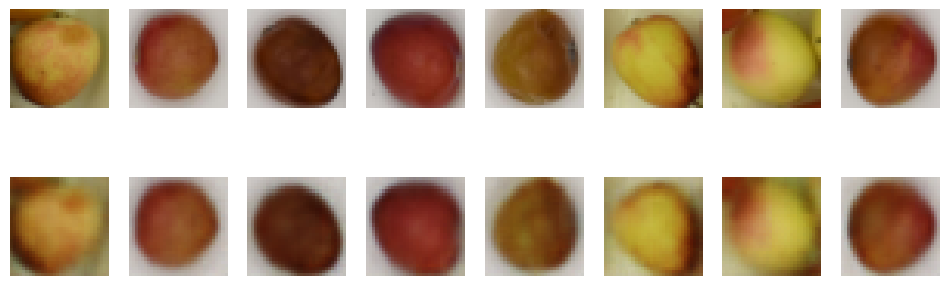

In [27]:
#test block
test_autoencoder(mse_ae, train_loader, device=device)


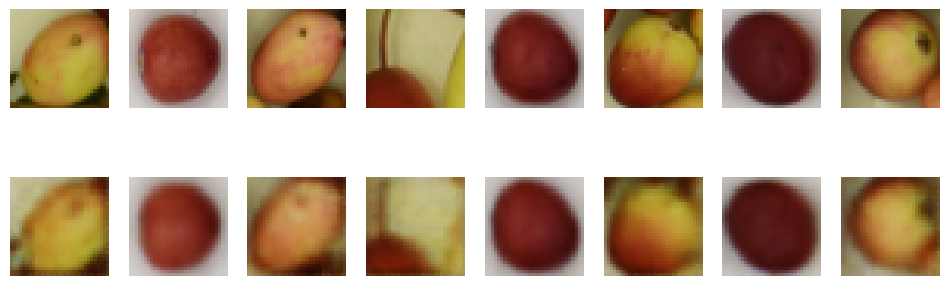

In [28]:
test_autoencoder(mae_ae, train_loader, device=device)

The mae looks like it generally maintains sharper images

4. This function tests interpolating between two images.  Try it with both the MSE and MAE autoencoders and compare the results.

In [29]:
def test_interpolation(encoder, decoder, train_ds, index1=100, index2=200, device='cpu', num_steps=10):
    """ Test interpolating between two random images from the dataset.

        Arguments:
            encoder: The encoder model.
            decoder: The decoder model.
            train_ds: The dataset to sample images from.
            index1: The index of the first image in the dataset. Defaults to 100.
            index2: The index of the second image in the dataset. Defaults to 200.
            device: The device to use for computation. Defaults to 'cpu'.
            num_steps: The number of steps for interpolation. Defaults to 10.
    """
    # test interpolating between images
    with torch.no_grad():
        # Get two random images from the dataset
        img1, _ = train_ds[index1]
        img2, _ = train_ds[index2]

        # Move images to device and add batch dimension
        img1 = img1.unsqueeze(0).to(device)
        img2 = img2.unsqueeze(0).to(device)

        # Encode the images
        encoded_img1 = encoder(img1)
        encoded_img2 = encoder(img2)

        # Interpolate between the two encoded images
        interpolated_images = []
        for alpha in np.linspace(0, 1, num_steps):
            interpolated_encoded = (1 - alpha) * encoded_img1 + alpha * encoded_img2
            reconstructed_image = decoder(interpolated_encoded)
            interpolated_images.append(reconstructed_image.squeeze(0).cpu().permute(1, 2, 0))

    # Plot the interpolated images
    fig, axes = plt.subplots(1, num_steps, figsize=(15, 3))
    for i in range(num_steps):
        axes[i].imshow(interpolated_images[i])
        axes[i].axis('off')
    plt.show()

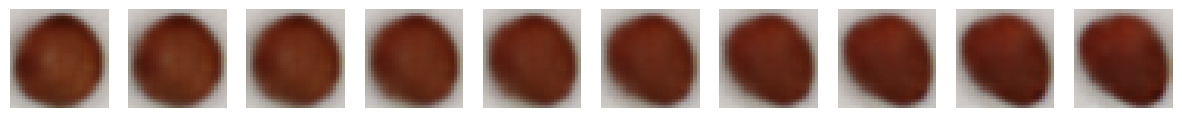

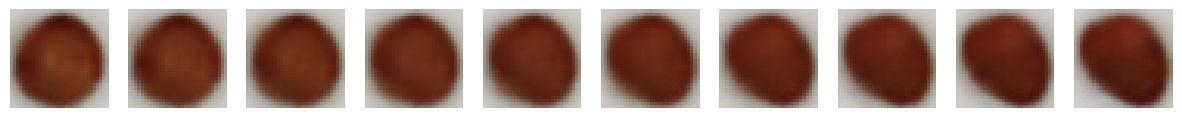

In [30]:
test_interpolation(mse_encoder, mse_decoder, train_ds, device=device)

test_interpolation(mae_encoder, mae_decoder, train_ds, device=device)


Looks roughly the same for both to be honest